# 4.1 Introduction to Probability Distributions

**Goal:** describe the distribution of a random variable, compute event probabilities and moments, and distinguish probability mass from density.

**Prerequisites:** Module 3 probability rules, conditioning, and counting; Module 0 sums and integrals.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. If needed, install them in your chosen environment with `python3 -m pip install numpy scipy matplotlib`. Open in JupyterLab, Jupyter Notebook, or VS Code with a Python kernel. Use **Restart Kernel and Run All** to reproduce the saved text and figure outputs. Every notebook is self-contained; random examples use a local fixed seed. All data are synthetic or idealized model calculations, and no downloads are needed.

## Module navigation

1. **Introduction** (this notebook)
2. [Discrete Probability Distributions](2_Discrete-Probability-Distributions.ipynb)
3. [Continuous Probability Distributions](3_Continuous-Probability-Distributions.ipynb)
4. [Important Distribution Concepts](4_Important-Distribution-Concepts.ipynb)
5. [Important Theorems](5_Important-Theorems.ipynb)

## Contents
1. What is a probability distribution?
2. Discrete distributions and PMFs
3. Continuous distributions and PDFs
4. Cumulative distribution functions
5. Expected value
6. Variance of a random variable
7. Standard deviation
8. ML applications, practice, and solutions

## 1. What is a Probability Distribution?

A **random variable** $X$ maps outcomes of a random experiment to numerical values. Its **probability distribution** specifies how probability is assigned to its possible values or sets of values. A variable is not the same as one observed realization $x$, and its distribution is not the same as a finite sample drawn from it.

**Worked example:** toss two independent fair coins and let $X$ be the number of heads. The ordered outcomes HH,HT,TH,TT are equally likely, but $X$ has probabilities $P(X=0)=1/4$, $P(X=1)=1/2$, $P(X=2)=1/4$. Compressing outcomes into a random variable can create unequal probabilities even from equally likely elementary outcomes.

A distribution includes both its **support** (allowed values, more precisely the region carrying probability) and its probability assignment. A named family, such as a normal distribution, becomes a specific model only after its parameters are supplied. Two models can have the same mean and variance yet assign very different tail probabilities.

## 2. Discrete Distributions; Probability Mass Function (PMF)

A discrete random variable takes values in a finite or countably infinite set. Its PMF is $p_X(x)=P(X=x)$ and must satisfy
$$p_X(x)\ge0,\qquad\sum_xp_X(x)=1.$$
For any event described by a set A, $P(X\in A)=\sum_{x\in A}p_X(x)$. Values outside the support have mass zero.

Counts, binary labels, and trial numbers are common examples. A discrete distribution need not have finite support, and its values need not be consecutive integers. Bernoulli, binomial, and Poisson models are developed in the next notebook.

P(X >= 1): 0.75


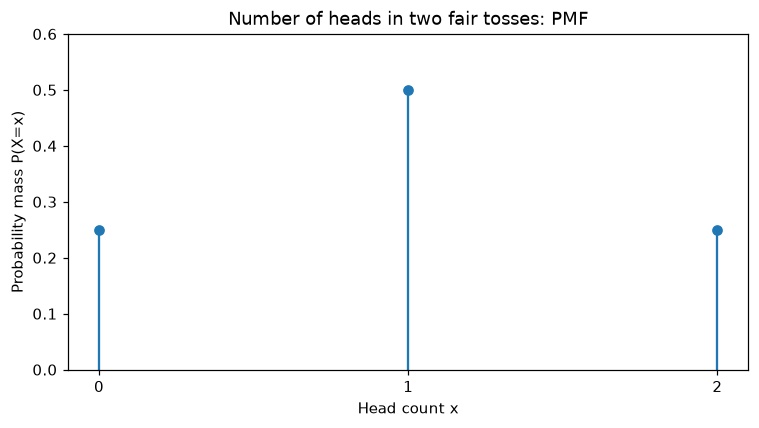

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate, special

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.size": 10})
rng = np.random.default_rng(2026)

values = np.array([0, 1, 2])
masses = np.array([0.25, 0.50, 0.25])
assert np.all(masses >= 0) and np.isclose(masses.sum(), 1)
print("P(X >= 1):", masses[values >= 1].sum())
fig, ax = plt.subplots()
ax.stem(values, masses, basefmt=" ")
ax.set(title="Number of heads in two fair tosses: PMF", xlabel="Head count x", ylabel="Probability mass P(X=x)", xticks=values, ylim=(0, 0.6))
fig.tight_layout()
plt.show()

## 3. Continuous Distributions; Probability Density Function (PDF)

An **absolutely continuous** random variable has a nonnegative density $f_X$ such that
$$\int_{-\infty}^{\infty}f_X(x)\,dx=1,\qquad P(a\le X\le b)=\int_a^bf_X(x)\,dx.$$
For these variables, $P(X=x)=0$ at every exact point. The density height $f_X(x)$ is **not** the probability of that point, may exceed 1, and has inverse measurement units. For a short interval of width $\Delta$ where density varies little, its probability is approximately $f_X(x)\Delta$.

**Worked example:** a uniform variable on $[0,0.2]$ has density 5 throughout the interval. Its total probability is $5(0.2)=1$, and $P(0.05\le X\le0.10)=5(0.05)=0.25$. Density 5 is valid; point probability 5 would not be.

In introductory use, “continuous distribution” usually means one with a PDF. More generally, not every distribution with no point masses has an ordinary density. A **mixed distribution** can also combine a point mass, such as zero spending, with a continuous positive amount. The discrete/absolutely-continuous distinction does not exhaust every mathematical possibility.

In [2]:
continuous = stats.uniform(loc=0, scale=0.2)  # scale is interval width
probability = continuous.cdf(0.10)-continuous.cdf(0.05)
area, error = integrate.quad(continuous.pdf, 0, 0.2)
print("Density at 0.1:", continuous.pdf(0.1))
print("Probability on [0.05, 0.10]:", probability)
print("Integral over support:", area)
assert np.isclose(probability, 0.25) and np.isclose(area, 1)

Density at 0.1: 5.0
Probability on [0.05, 0.10]: 0.25
Integral over support: 1.0


## 4. Cumulative Distribution Function (CDF)

Every real-valued random variable has a CDF
$$F_X(x)=P(X\le x).$$
It is nondecreasing, right-continuous, approaches 0 toward $-\infty$ and 1 toward $+\infty$, and always lies in [0,1]. CDFs work for discrete, continuous, and mixed distributions.

A universal interval formula is $P(a<X\le b)=F(b)-F(a)$. For a discrete variable, closed endpoints matter: $P(a\le X\le b)=F(b)-F(a^-)$, where $F(a^-)$ is the left limit. At a point, $P(X=a)=F(a)-F(a^-)$. For an integer-valued variable, the left limit at integer a is $F(a-1)$. In an absolutely continuous model, singleton probabilities vanish, so endpoint inclusion does not change interval probabilities.

The CDF of a discrete variable has jumps equal to its point masses. A PDF can be recovered as $F'(x)$ where the derivative-density relation holds. The **survival function** is $S(x)=1-F(x)=P(X>x)$; library `sf` methods can be more accurate than subtracting a CDF extremely close to 1.

P(1 <= X <= 2): 0.75
P(1 < X <= 2): 0.25
P(X=1), the CDF jump: 0.5


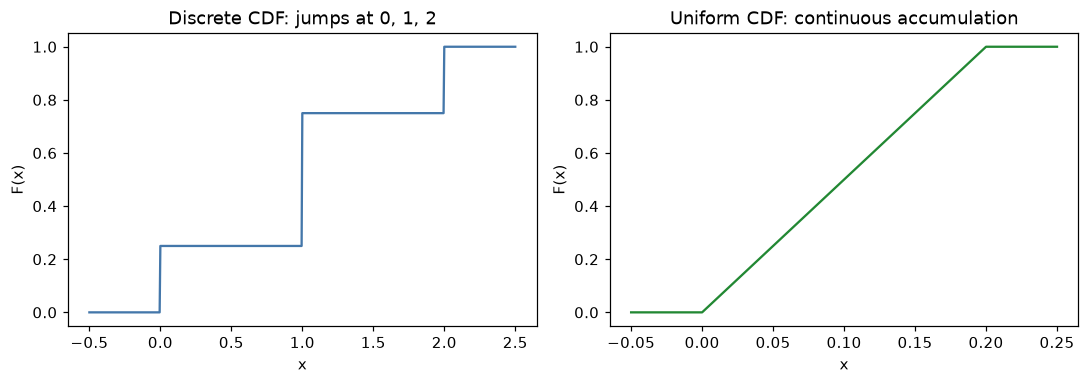

In [3]:
coin_count = stats.binom(n=2, p=0.5)
print("P(1 <= X <= 2):", coin_count.cdf(2)-coin_count.cdf(0))
print("P(1 < X <= 2):", coin_count.cdf(2)-coin_count.cdf(1))
print("P(X=1), the CDF jump:", coin_count.cdf(1)-coin_count.cdf(0))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
grid = np.linspace(-0.5, 2.5, 601)
axes[0].plot(grid, coin_count.cdf(grid), color="#4477AA")
axes[0].set(title="Discrete CDF: jumps at 0, 1, 2", xlabel="x", ylabel="F(x)", ylim=(-0.05, 1.05))
x = np.linspace(-0.05, 0.25, 301)
axes[1].plot(x, continuous.cdf(x), color="#228833")
axes[1].set(title="Uniform CDF: continuous accumulation", xlabel="x", ylabel="F(x)", ylim=(-0.05, 1.05))
fig.tight_layout()
plt.show()

## 5. Expected Value

Expected value is a probability-weighted center. Provided the appropriate absolute expectation is finite,
$$\mathbb E[X]=\sum_xxp_X(x)\quad\text{or}\quad\mathbb E[X]=\int xf_X(x)\,dx.$$
It need not be a possible observed value: a fair die has expectation 3.5 even though it never lands on 3.5. “Expected” does not mean guaranteed, most likely, or the next result.

For a function g, $\mathbb E[g(X)]=\sum_xg(x)p_X(x)$ or the corresponding density integral. Linearity gives $\mathbb E[aX+bY+c]=a\mathbb E[X]+b\mathbb E[Y]+c$ without needing independence, when expectations exist. In general, $\mathbb E[g(X)]\ne g(\mathbb E[X])$ for nonlinear g.

**Worked example:** the two-toss head count has expectation $0(1/4)+1(1/2)+2(1/4)=1$. Its expected square is 1.5, not the square of its mean (1). A model's expected loss is similarly an average of a loss function over possible outcomes, not merely loss evaluated at an average outcome.

In [4]:
expected = np.sum(values*masses)
expected_square = np.sum(values**2*masses)
print("E[X]:", expected, "E[X^2]:", expected_square)
die = stats.randint(low=1, high=7)  # high is excluded
print("Fair-die expectation:", die.mean())
print("E[2X+3]:", np.sum((2*values+3)*masses))
assert np.isclose(expected, 1) and np.isclose(expected_square, 1.5)

E[X]: 1.0 E[X^2]: 1.5
Fair-die expectation: 3.5
E[2X+3]: 5.0


## 6. Variance of a Random Variable

With a finite second moment and mean $\mu$,
$$\operatorname{Var}(X)=\mathbb E[(X-\mu)^2]=\mathbb E[X^2]-\mu^2.$$
Variance measures spread in squared units and is nonnegative. These are model expectations, not a sample variance estimator with denominator $n-1$. Not all probability distributions have finite moments; a PDF integrating to 1 does not guarantee a finite mean or variance.

For constants a,b, $\operatorname{Var}(aX+b)=a^2\operatorname{Var}(X)$. For two variables with finite variances,
$$\operatorname{Var}(X+Y)=\operatorname{Var}(X)+\operatorname{Var}(Y)+2\operatorname{Cov}(X,Y).$$
Independence implies zero covariance, allowing variances to add. Zero covariance by itself does not generally imply independence.

**Worked example:** the head-count variance is $1.5-1^2=0.5$. If two toss indicators are independent Bernoulli(0.5), each variance is 0.25 and the sum variance is also 0.5.

## 7. Standard Deviation

The standard deviation is $\sigma=\sqrt{\operatorname{Var}(X)}$. It restores the original units; head-count SD here is $\sqrt{0.5}\approx0.7071$. A standard error instead describes variability of an estimator across hypothetical samples. Notebook 4.5 distinguishes the distribution of observations from the sampling distribution of a mean.

In [5]:
variance = np.sum((values-expected)**2*masses)
print("Variance:", variance, "SD:", np.sqrt(variance))
assert np.isclose(variance, expected_square-expected**2)
assert np.isclose(variance, coin_count.var())
# Continuous example: uniform on [0, 0.2].
mean_integral, _ = integrate.quad(lambda x: x*continuous.pdf(x), 0, 0.2)
var_integral, _ = integrate.quad(lambda x: (x-mean_integral)**2*continuous.pdf(x), 0, 0.2)
print("Uniform mean:", mean_integral, "variance:", var_integral)
assert np.isclose(var_integral, 0.2**2/12)

Variance: 0.5 SD: 0.7071067811865476
Uniform mean: 0.1 variance: 0.0033333333333333335


## 8. AI/ML applications

- **Probabilistic classification:** a binary target given inputs can be modeled by $Y\mid x\sim\operatorname{Bernoulli}(p(x))$. Logistic regression sets $p(x)$ using a sigmoid score. This models a conditional label distribution, not a continuous label density.
- **Generative models:** sample latent variables and observations from specified distributions to generate synthetic examples. A realistic-looking sample alone does not establish faithful coverage of the real distribution.
- **Uncertainty estimation:** a predictive distribution can report interval probabilities and quantiles rather than only a point prediction. Its validity still depends on fitting, evaluation, and deployment conditions.

**Worked example:** for a binary outcome with $p=0.8$, expectation is 0.8 and variance is 0.16, while actual outcomes remain only 0 or 1. Outcome variability is different from uncertainty about the fitted value of p.

In [6]:
p = 0.8
label_model = stats.bernoulli(p)
print("Binary outcome mean:", label_model.mean(), "variance:", label_model.var())
print("Ten generated labels:", label_model.rvs(size=10, random_state=rng).tolist())
assert np.isclose(label_model.var(), p*(1-p))

Binary outcome mean: 0.8 variance: 0.15999999999999992
Ten generated labels: [1, 1, 1, 1, 1, 1, 0, 1, 1, 1]


## Practice

1. A random variable takes 0,1,3 with masses 0.2,0.5,0.3. Find its mean, variance, and SD.
2. Can a density value be 4? Can a point probability be 4?
3. For the two-toss head count, find $P(1\le X\le2)$ and $P(1<X\le2)$.
4. If $Y=3X-2$ and $\operatorname{Var}(X)=4$, find $\operatorname{Var}(Y)$ and its SD.
5. Does $\mathbb E[X]=2.4$ imply 2.4 is an allowed observed value?
6. Must independent X and Y have $\operatorname{Var}(X+Y)=\operatorname{Var}(X)+\operatorname{Var}(Y)$? State the moment requirement.
7. What is wrong with using a PDF value directly as the probability that a measurement equals exactly that value?

## Solutions

1. Mean $0+0.5+0.9=1.4$. Second moment $0+0.5+2.7=3.2$. Variance $3.2-1.4^2=1.24$; SD $\sqrt{1.24}\approx1.11355$.
2. A density can be 4 because area, not height alone, is probability. A point probability must lie in [0,1].
3. $0.75$ and $0.25$, respectively; inclusion of 1 matters for a discrete variable.
4. Variance $3^2(4)=36$; SD 6. The shift -2 changes neither spread measure.
5. No. An expectation is a weighted center and need not belong to the support.
6. Yes, when variances are finite; independence eliminates covariance. Infinite moments require separate treatment.
7. In an absolutely continuous model a singleton has probability zero; integrate the density over a meaningful interval or measurement-resolution bin instead.

**Readiness check:** specify a random variable and its support, distinguish PMF/PDF/CDF, and compute moments with the appropriate sums or integrals.

**Next:** [4.2 Discrete Probability Distributions](2_Discrete-Probability-Distributions.ipynb).